# 04 · EDA: titles and abstracts

**Needs:** the merged files from notebook 02. **Produces:** nothing.

Questions for this notebook:
1. How long are titles and abstracts, and does it depend on sector or office?
2. How good is the text? (placeholders, truncated abstracts, other languages)
3. What does the vocabulary look like?
4. Which words characterise each field?
5. Which fields use similar words?
6. How much text is duplicated?

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

PROC = Path("../data/processed")
by_field = pd.read_parquet(PROC / "patents_2021-2026_by_field.parquet")
by_pub = pd.read_parquet(PROC / "patents_2021-2026_by_publication.parquet")

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 110)

SECTORS = ["Electrical engineering", "Instruments", "Chemistry", "Mechanical engineering"]
COLORS = dict(zip(SECTORS, ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]))
by_field["field"] = by_field["wipo_field_number"].astype(str).str.zfill(2) + " " + by_field["wipo_field_name"]
field_order = sorted(by_field["field"].unique())

## 1. Length

Length in words, by sector. The box is the middle half of the data, the line is the median.
Very long abstracts are hidden to keep the plot readable.

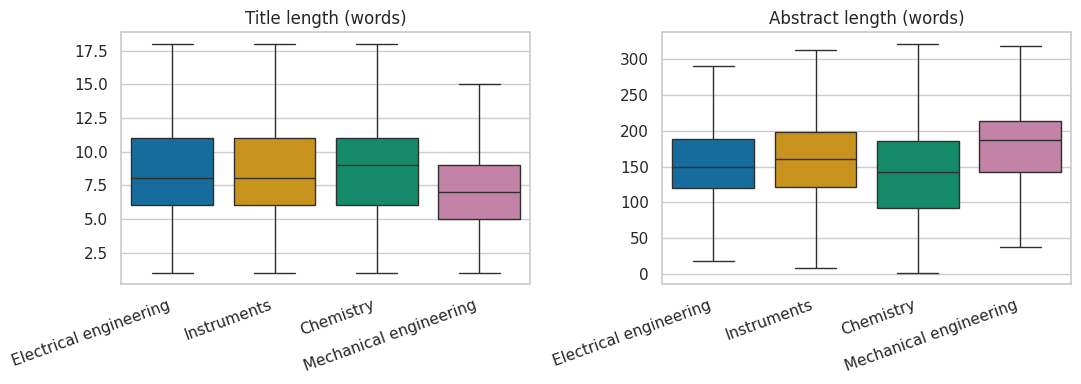

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in [(axes[0], "title_n_words", "Title length (words)"), (axes[1], "abstract_n_words", "Abstract length (words)")]:
    sns.boxplot(data=by_field, x="wipo_sector", y=col, order=SECTORS, palette=COLORS, showfliers=False, ax=ax, hue="wipo_sector", legend=False)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title)
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [3]:
by_field.groupby("wipo_sector")[["title_n_words", "abstract_n_words"]].describe().T.loc[:, SECTORS].round(1)

wipo_sector             Electrical engineering  Instruments  Chemistry  Mechanical engineering
title_n_words    count                 16000.0      10000.0    22000.0                 16000.0
                 mean                      8.5          8.4        9.1                     7.4
                 std                       3.9          3.9        4.2                     3.6
                 min                       1.0          1.0        1.0                     1.0
                 25%                       6.0          6.0        6.0                     5.0
                 50%                       8.0          8.0        9.0                     7.0
                 75%                      11.0         11.0       11.0                     9.0
                 max                      52.0         46.0       67.0                    51.0
abstract_n_words count                 16000.0      10000.0    22000.0                 16000.0
                 mean                    152.1        157.7      138.2                   176.8
                 std                      47.4         52.9       59.7                    50.1
                 min                       6.0          5.0        2.0                     1.0
                 25%                     120.0        122.0       92.0                   143.0
                 50%                     150.0        161.0      142.0                   187.0
                 75%                     188.0        198.0      186.0                   213.0
                 max                     474.0        899.0      683.0                   453.0

Does length depend on the **patent office**? Median abstract length for the largest offices:

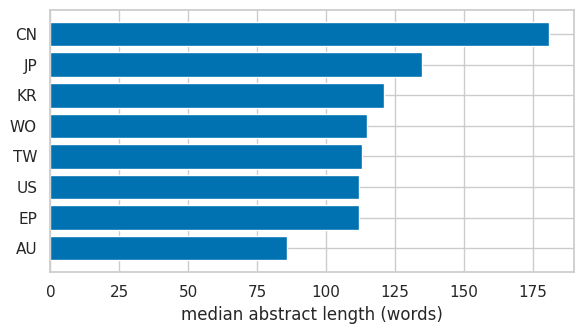

In [4]:
main = by_pub["office"].value_counts().head(8).index
med = by_pub[by_pub["office"].isin(main)].groupby("office")["abstract_n_words"].median().sort_values()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(med.index, med.values, color="#0072B2")
ax.set_xlabel("median abstract length (words)")
plt.tight_layout()
plt.show()

And by **field**: the shortest and longest median abstracts.

In [5]:
med_field = by_field.groupby("field")["abstract_n_words"].median().sort_values()
pd.concat([med_field.head(5), med_field.tail(5)]).rename("median words")

field
16 Pharmaceuticals                        81.0
14 Organic fine chemistry                 97.5
15 Biotechnology                         106.0
17 Macromolecular chemistry, polymers    130.0
19 Basic materials chemistry             137.0
25 Handling                              191.0
31 Mechanical elements                   191.0
30 Thermal processes and apparatus       192.0
23 Chemical engineering                  194.0
26 Machine tools                         195.0
Name: median words, dtype: float64

## 2. Text quality

Notebook 02 added flags. How many rows have a problem, by sector?

In [6]:
flags = ["abstract_is_placeholder", "abstract_is_short", "abstract_has_cjk"]
by_field.groupby("wipo_sector")[flags].sum().loc[SECTORS]

,abstract_is_placeholder,abstract_is_short,abstract_has_cjk
wipo_sector,,,
Electrical engineering,0,4,1
Instruments,0,9,1
Chemistry,2,74,0
Mechanical engineering,1,8,3


In [7]:
# the shortest abstracts
by_pub.nsmallest(8, "abstract_n_chars")[["publication_number", "abstract_clean"]]

,publication_number,abstract_clean
52197,TW-M646051-U,(無)
48775,JP-2026049542-A,"COPYRIGHT: (C)2026,JPO"
2529,CN-110191641-B,Novel lactonases are provided.
139,AU-2019374871-A1,The compounds disclosed herein (
15,AU-2016338673-B2,The present invention provides an
44765,EP-3828144-A1,Information on abstract not available
54940,US-12114026-B2,A system for queuing flows to channels.
18243,CN-117643051-A,A system for reconstructing video frames.


In [8]:
# the longest abstract: is it really an abstract?
longest = by_pub.nlargest(1, "abstract_n_chars").iloc[0]
print(longest["publication_number"], "-", longest["abstract_n_chars"], "characters")
print(longest["abstract_clean"][:600], "...")

WO-2023217642-A1 - 4038 characters
The invention relates to a process for the preparation of a polypropylene composition comprising a heterophasic propylene copolymer wherein the heterophasic propylene copolymer consists of: a propylene homopolymer matrix in an amount from 71 to 92 wt%, preferably from 78 to 89 wt%, more preferably from 83 to 87 wt%, based on the heterophasic propylene copolymer and an ethylene-propylene copolymer in an amount from 8 to 29 wt%, preferably from 11 to 22 wt%, more preferably 13 to 17 wt%, based on the heterophasic propylene copolymer, wherein the amount of units derived from ethylene based on the ...


Few problems, but they exist. For text modelling you can decide to drop `abstract_is_placeholder` rows.
OCR noise (page numbers, figure labels inside the abstract) is **not** flagged: it is hard to detect.

## 3. Vocabulary

We count in how many publications each word appears (document frequency), ignoring common English words.
We use distinct publications.

In [9]:
token = r"(?u)\b[a-zA-Z][a-zA-Z\-]{2,}\b"          # words with at least 3 letters
vec = CountVectorizer(stop_words="english", token_pattern=token, min_df=5, binary=True)
X = vec.fit_transform(by_pub["abstract_clean"])

doc_freq = pd.Series(np.asarray(X.sum(axis=0)).ravel(), index=vec.get_feature_names_out()).sort_values(ascending=False)
print("distinct words appearing in at least 5 abstracts:", len(doc_freq))
doc_freq.head(30).to_frame("publications")

distinct words appearing in at least 5 abstracts: 18638


,publications
comprises,32596
invention,27000
method,23077
discloses,22392
relates,20983
device,20796
field,19856
model,16918
technical,16395
provided,15805


The most frequent words are generic patent language ("invention", "method", "device"), not technology.
This is why we need weighting (TF-IDF) to find words that characterise a field.

Word frequencies follow a **Zipf law**: a few words are very frequent, most words are rare. On a log-log plot it is close to a straight line.

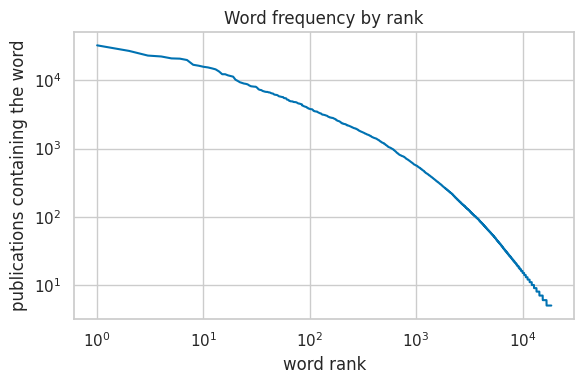

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(np.arange(1, len(doc_freq) + 1), doc_freq.values, color="#0072B2")
ax.set_xlabel("word rank")
ax.set_ylabel("publications containing the word")
ax.set_title("Word frequency by rank")
plt.tight_layout()
plt.show()

### How abstracts start

Abstracts follow conventions. The first four words:

In [11]:
opening = by_pub["abstract_clean"].str.lower().str.split().str[:4].str.join(" ")
opening.value_counts().head(15)

abstract_clean
the utility model discloses       7294
the invention discloses a         7136
the invention relates to          6062
the utility model relates         3929
the invention provides a          3020
the present invention relates     2168
the utility model provides        1926
the invention belongs to          1714
the invention discloses an        1476
the application relates to        1271
the application discloses a        923
the embodiment of the              849
the utility model belongs          843
the application provides a         770
the present invention provides     684
Name: count, dtype: int64

Do offices write in different styles? The five most common openings, as a share of each office's abstracts:

In [12]:
top_open = opening.value_counts().head(5).index
tab = pd.crosstab(by_pub["office"], opening.where(opening.isin(top_open), "other"), normalize="index")
tab.loc[by_pub["office"].value_counts().head(6).index].style.format("{:.0%}")

abstract_clean,other,the invention discloses a,the invention provides a,the invention relates to,the utility model discloses,the utility model relates
office,,,,,,
CN,38%,16%,7%,12%,17%,9%
US,98%,0%,0%,2%,0%,0%
WO,94%,0%,0%,6%,0%,0%
EP,91%,0%,0%,8%,0%,0%
JP,100%,0%,0%,0%,0%,0%
KR,100%,0%,0%,0%,0%,0%


## 4. Words that characterise each field

We join all text of a field (title + abstract) into one document, giving 32 documents.
TF-IDF gives a high weight to words that are frequent in one field and rare in the others.
Words found in more than 30% of the fields are dropped (`max_df=0.3`), which removes the generic patent language.
We also ignore words that appear in fewer than 30 publications: they are too rare to describe a field.

In [13]:
field_docs = (by_field.assign(text=by_field["title_clean"] + ". " + by_field["abstract_clean"])
              .groupby("field")["text"].apply(" ".join).loc[field_order])

tfidf = TfidfVectorizer(stop_words="english", token_pattern=token, sublinear_tf=True, max_df=0.3, min_df=2)
F = tfidf.fit_transform(field_docs)
terms = np.array(tfidf.get_feature_names_out())

# keep only words that are not too rare in the whole corpus (document frequency computed in section 3)
frequent_enough = np.isin(terms, doc_freq[doc_freq >= 30].index)


def top_words(i, n=8):
    weights = F[i].toarray().ravel() * frequent_enough
    return ", ".join(terms[np.argsort(-weights)[:n]])


top_terms = pd.Series({field: top_words(i) for i, field in enumerate(field_docs.index)}, name="top terms")
top_terms.to_frame()

,top terms
"01 Electrical machinery, apparatus, energy","luminance, mosfet, phase-locked, throttling, sword, nanocrystalline, intercalation, non-display"
02 Audio-visual technology,"bitstream, sub-pixels, conference, playback, luminance, decoded, non-display, sub-pixel"
03 Telecommunications,"csi, microstrip, mimo, downlink, baseband, uplink, terahertz, codeword"
04 Digital communication,"sidelink, blockchain, csi, downlink, uplink, token, forwarding, policy"
05 Basic communication processes,"voltage-controlled, codeword, nmos, microstrip, phase-locked, digital-to-analog, pmos, parity"
06 Computer technology,"keywords, blockchain, keyword, hash, metadata, token, asset, policy"
07 IT methods for management,"blockchain, keywords, token, credit, merchant, provider, transactions, asset"
08 Semiconductors,"electroluminescent, sub-pixels, non-display, sub-pixel, gan, pmos, mosfet, optoelectronic"
09 Optics,"photonic, sub-pixels, head-mounted, pupil, multiplexer, terahertz, optoelectronic, luminance"
10 Measurement,"sampler, nanopore, doppler, thermocouple, wavelet, aptamer, time-frequency, subjective"


A quick sanity check: the terms should look like the field name. If they do not, the field is heterogeneous or the sample is dominated by a sub-topic.

## 5. Which fields use similar words?

Cosine similarity between the 32 TF-IDF vectors: 1 means identical vocabulary, 0 nothing in common.
This is a first, simple version of the question "does text recover the technology structure?".

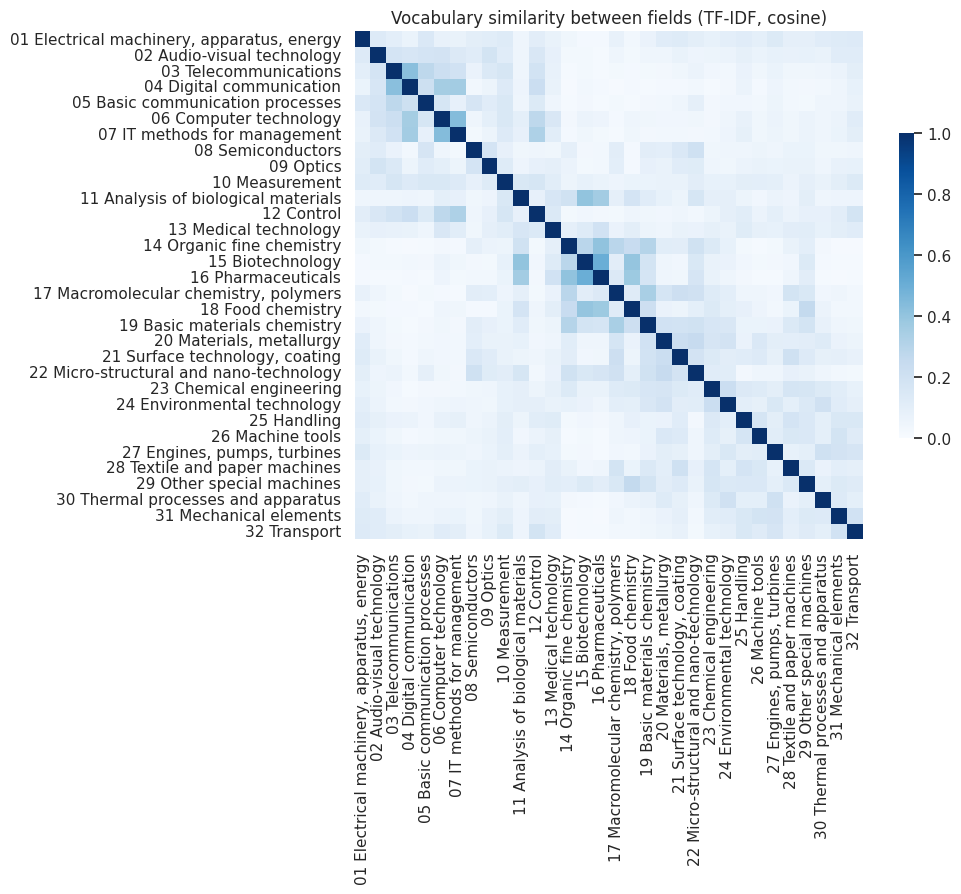

In [14]:
S = pd.DataFrame(cosine_similarity(F), index=field_docs.index, columns=field_docs.index)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(S, cmap="Blues", vmin=0, square=True, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Vocabulary similarity between fields (TF-IDF, cosine)")
plt.tight_layout()
plt.show()

In [15]:
# the ten most similar pairs of different fields
pairs = S.where(np.triu(np.ones(S.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
pairs.head(10).rename("similarity").round(2)

field                                field                       
15 Biotechnology                     16 Pharmaceuticals              0.50
06 Computer technology               07 IT methods for management    0.44
03 Telecommunications                04 Digital communication        0.42
14 Organic fine chemistry            16 Pharmaceuticals              0.41
11 Analysis of biological materials  15 Biotechnology                0.40
15 Biotechnology                     18 Food chemistry               0.40
16 Pharmaceuticals                   18 Food chemistry               0.38
11 Analysis of biological materials  16 Pharmaceuticals              0.36
04 Digital communication             07 IT methods for management    0.36
                                     06 Computer technology          0.35
Name: similarity, dtype: float64

In [16]:
# nearest field of each field
nearest = S.where(~np.eye(len(S), dtype=bool)).idxmax()
nearest_sim = S.where(~np.eye(len(S), dtype=bool)).max()
pd.DataFrame({"nearest field": nearest, "similarity": nearest_sim.round(2)})

,nearest field,similarity
field,,
"01 Electrical machinery, apparatus, energy",05 Basic communication processes,0.15
02 Audio-visual technology,06 Computer technology,0.19
03 Telecommunications,04 Digital communication,0.42
04 Digital communication,03 Telecommunications,0.42
05 Basic communication processes,03 Telecommunications,0.28
06 Computer technology,07 IT methods for management,0.44
07 IT methods for management,06 Computer technology,0.44
08 Semiconductors,22 Micro-structural and nano-technology,0.20
09 Optics,02 Audio-visual technology,0.18


## 6. Duplicated text

**Titles.** Many are generic.

In [17]:
by_pub["title_clean"].str.lower().value_counts().head(10)

title_clean
display device                      90
system                              43
semiconductor device                42
display panel and display device    38
electronic device                   30
image forming apparatus             22
air conditioner                     19
resin composition                   14
display apparatus                   13
substrate processing apparatus      11
Name: count, dtype: int64

**Abstracts.** The same abstract in several publications. It is rare, and it has two causes: very generic abstracts, and several
publications derived from the same application (for example a US application and its continuation).

In [18]:
# share of each office's publications whose abstract appears more than once
dup_by_office = by_pub.groupby("office")["abstract_is_duplicate"].mean()
dup_by_office.loc[by_pub["office"].value_counts().head(8).index].round(3)

office
CN    0.001
US    0.011
WO    0.004
EP    0.009
JP    0.000
KR    0.000
TW    0.001
AU    0.010
Name: abstract_is_duplicate, dtype: float64

In [19]:
# the largest group of publications with exactly the same abstract
key = by_pub["abstract_clean"].str.lower()
group = by_pub[key.isin(key[key.duplicated()].value_counts().index[:1])]
print(len(group), "publications share this abstract:\n")
print(group["abstract_clean"].iloc[0][:300], "...\n")
group[["publication_number", "office", "title_clean"]].head(8)

3 publications share this abstract:

The present invention provides compounds, compositions thereof, and methods of using the same. ...



,publication_number,office,title_clean
52785,US-11117889-B1,US,IRAK degraders and uses thereof
55054,US-12168057-B2,US,IRAK degraders and uses thereof
60520,US-2026125400-A1,US,Tyk2 degraders and uses thereof


Exact duplicates are few, but **near-duplicates** (family members with slightly different text) are not counted here.
If you train a model and evaluate on a random split, copies of the same invention can end up in both the training
and the test set. Keep this in mind for later work.

## What to take away

- **Length differs by sector.** Mechanical engineering has the longest abstracts and the shortest titles; Chemistry has shorter abstracts,
  with Pharmaceuticals and Organic fine chemistry at the bottom (many abstracts are short formula-based summaries).
- **Style differs by office.** Many Chinese abstracts open with "The utility model discloses" or "The invention discloses", which is rare elsewhere.
  A model trained on this text may learn the office style together with the technology.
- **Text quality is good overall.** Only a handful of placeholders; the short-abstract flag needs a manual look.
- **Vocabulary is dominated by generic patent language**; field-specific words appear only after weighting.
- **Similar fields use similar words.** The closest pairs are Biotechnology / Pharmaceuticals, Computer technology / IT methods for management,
  and Telecommunications / Digital communication. Fields in different sectors are much less similar.

## Try it yourself

1. Rebuild the field table with `max_df=0.5`. What changes?
2. Are Chinese abstracts shorter than US abstracts in every sector?
3. Pick two fields with high similarity. Read 5 abstracts from each. Are they really close in content?